# 05 · Validation: is the bubble confidence better than luck?

This notebook presents the output of `lppl validate` (see `docs/validation.md`). Every test
compares the LPPLS **positive confidence** with fair references:

| Reference | Question it answers |
|---|---|
| **base rate** | is the model better than a random guess? |
| **momentum score** (trailing 6-month return in σ units) | is it better than a trivial "it went up a lot" rule? |
| **time-shifted placebo** | is the *timing* of the signal informative, or just its general level? |
| **bubble-free simulated prices** | how often does it fire when no bubble can exist? |

**Event** being predicted: within the next 63 trading days, a fall from the running peak
of at least 1.5 × the asset's normal volatility × √63 (about 12 % for the S&P 500, 32 % for NVDA).

The notebook loads the newest report in `reports/validation/`. If there is none, it runs a
quick validation (no null-model rescans and no walk-forward re-tuning).

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from lppl import validation as V, viz
viz.apply_style()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

report_dir = V.latest_report_dir()
if report_dir is None:
    from lppl import pipeline
    from lppl.data import db
    engine = db.get_engine()
    run_id = pipeline.resolve_run(engine, label="default")
    rep = V.run_validation(engine, run_id, "default", run_walk_forward=False, run_null=False)
    report_dir = V.save_report(rep, V.PROJECT_ROOT / "reports" / "validation" / f"default_{run_id[:8]}")
rep = V.load_report(report_dir)
S, T = rep.summary, rep.tables
figs = dict(V.figures(rep))
plt.close("all")
display(Markdown(f"**Report:** `{report_dir.name}` · scan run `{S['run_id'][:8]}` (label `{S['label']}`)"))

**Report:** `default_8264c9f6` · scan run `8264c9f6` (label `default`)

## Verdict

Plain yes / no answers at the 5 % level. *Validation* = analysis dates from 2024 onwards,
which were never used to choose any setting.

In [2]:
names = {
    "beats_base_rate_all_dates": "better than a random guess (all dates)",
    "beats_base_rate_validation": "better than a random guess (2024+, unseen)",
    "beats_momentum_all_dates": "better than the momentum rule (all dates)",
    "beats_momentum_validation": "better than the momentum rule (2024+, unseen)",
    "beats_time_shifted_placebo": "timing matters (beats time-shifted placebo)",
    "calibrated_monotone": "higher confidence = more events (calibration)",
    "fires_more_on_real_than_bubble_free_prices": "fires more on real prices than on bubble-free paths",
}
pd.DataFrame({"test": [names[k] for k in S["verdict"]],
              "result": ["✔ yes" if v else ("✘ no" if v is False else "– not run") for v in S["verdict"].values()]})

,test,result
0,better than a random guess (all dates),✘ no
1,"better than a random guess (2024+, unseen)",✘ no
2,better than the momentum rule (all dates),✘ no
3,"better than the momentum rule (2024+, unseen)",✘ no
4,timing matters (beats time-shifted placebo),✘ no
5,higher confidence = more events (calibration),✘ no
6,fires more on real prices than on bubble-free ...,✘ no


## 1 · Skill

*Average precision* (AP) ranks dates by the score and measures how well the high-scored dates
coincide with events. A random score has AP equal to the **base rate**. Precision and recall
are given at the alarm threshold (confidence ≥ 0.3).

In [3]:
T["skill"].set_index("split").round(3)

,n,events,base_rate,ap_lppl,ap_momentum,lift_lppl,lift_momentum,precision_at_alarm,recall_at_alarm,alarm_rate_at_alarm
split,,,,,,,,,,
all,2304,304,0.132,0.135,0.137,1.022,1.036,0.095,0.026,0.036
train,1440,211,0.147,0.156,0.147,1.065,1.001,0.154,0.028,0.027
valid,792,92,0.116,0.120,0.132,1.030,1.140,0.045,0.022,0.056


## 2 · Calibration

If the confidence carries information, the share of dates followed by an event should rise
from band to band.

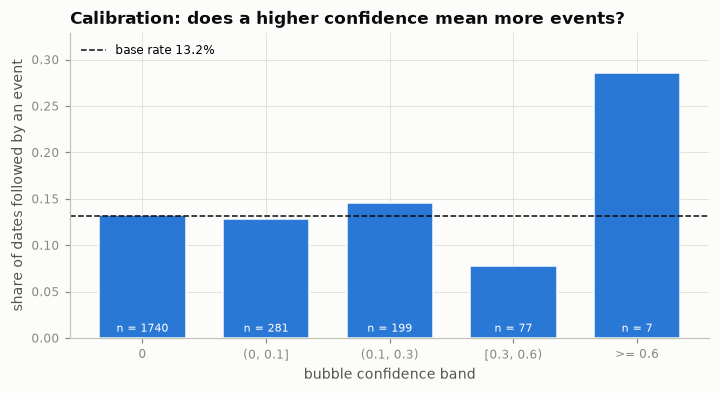

,band,n,event_rate,mean_fwd_dd
0,0,1740,0.133,-0.151
1,"(0, 0.1]",281,0.128,-0.150
2,"(0.1, 0.3)",199,0.146,-0.153
3,"[0.3, 0.6)",77,0.078,-0.144
4,>= 0.6,7,0.286,-0.261


In [4]:
display(figs["calibration.png"]); T["calibration"].round(3)

## 3 · Block bootstrap

Labels of nearby dates overlap: a 63-day horizon spans about six analysis dates. Resampling
whole calendar months keeps that dependence, so the intervals are honest. **If an interval
crosses 0, the difference is not statistically significant.**

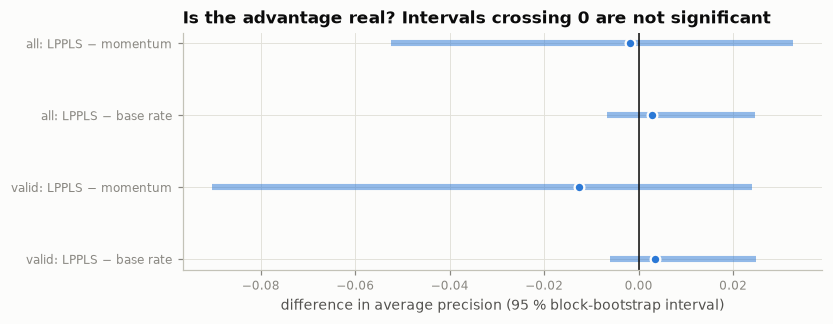

,split,metric,point,ci_low,ci_high,share_above_0,n_blocks
0,all,ap_lppl,0.135,0.091,0.185,NaN,92
3,all,lppl_minus_momentum,-0.002,-0.053,0.033,0.494,92
4,all,lppl_minus_base,0.003,-0.007,0.025,0.711,92
5,valid,ap_lppl,0.120,0.059,0.201,NaN,32
8,valid,lppl_minus_momentum,-0.013,-0.090,0.024,0.237,32
9,valid,lppl_minus_base,0.004,-0.006,0.025,0.724,32


In [5]:
display(figs["bootstrap.png"])
T["bootstrap"].query("metric in ['lppl_minus_base', 'lppl_minus_momentum', 'ap_lppl']").round(3)

## 4 · Placebo test

Each ticker's confidence series is shifted in time by a random amount (at least six months),
while the events stay where they are. A score whose *timing* matters should beat almost all
shifted versions (small p-value).

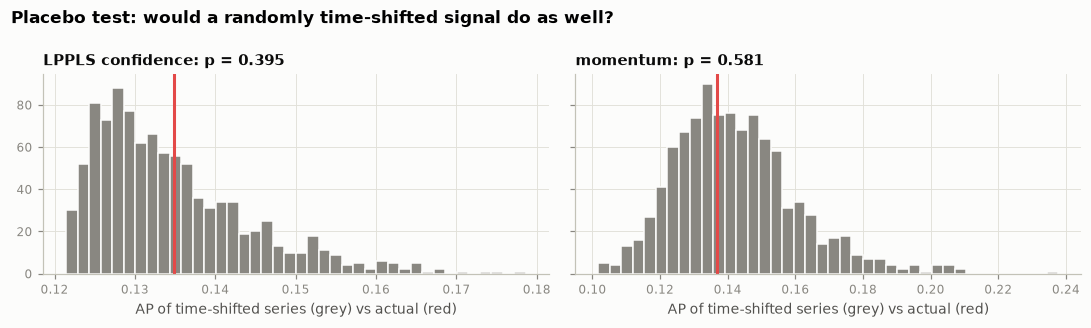

,score,actual_ap,placebo_mean,placebo_p95,p_value
0,conf,0.135,0.135,0.154,0.395
1,momentum,0.137,0.142,0.175,0.581


In [6]:
display(figs["placebo.png"]); T["placebo"].round(3)

## 5 · Robustness to the event definition

Lift = AP / base rate (1 = random). A real effect should not depend on one lucky choice of
horizon and threshold.

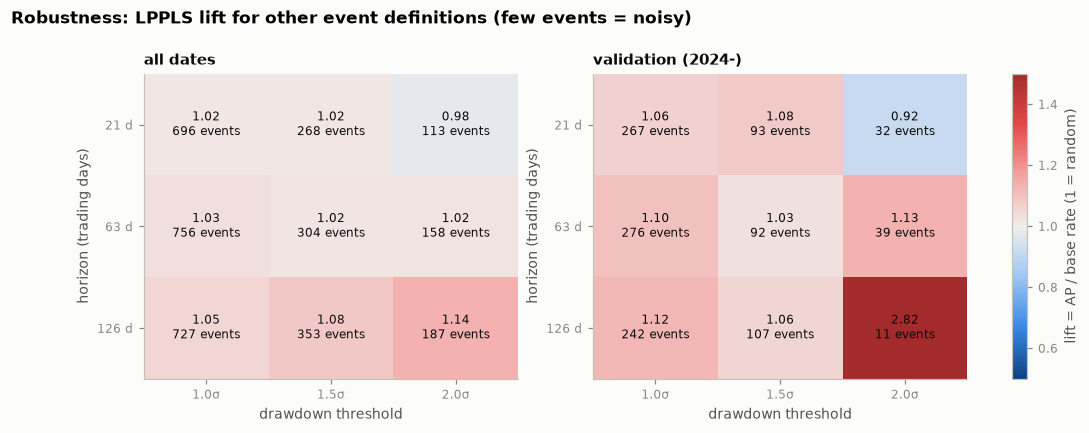

lift_lppl             lift_momentum            
k_sigma             1.0   1.5   2.0           1.0   1.5   2.0
split horizon                                                
all   21           1.02  1.02  0.98          0.99  1.03  1.57
      63           1.03  1.02  1.02          0.97  1.04  1.36
      126          1.05  1.08  1.14          0.94  1.01  1.21
valid 21           1.06  1.08  0.92          1.05  0.95  0.86
      63           1.10  1.03  1.13          1.05  1.14  0.95
      126          1.12  1.06  2.82          1.28  1.00  2.38

In [7]:
display(figs["grid.png"])
T["grid"].pivot_table(index=["split", "horizon"], columns="k_sigma", values=["lift_lppl", "lift_momentum"]).round(2)

## 6 · Timing of alarm episodes

An *episode* is a run of alarm dates (confidence ≥ 0.3) of one ticker. For each one: how long
after the first alarm the price topped (within 6 months), how much it rose first and fell
afterwards, and whether the top fell inside the model's estimated end window (`tc`).

In [8]:
tm = T["timing"]
done = tm[tm["complete"]]
display(Markdown(
    f"**{len(done)} completed episodes** · median lead from first alarm to top **{done.lead_trading_days.median():.0f} trading days** · "
    f"median rise to top **{done.gain_to_top.median():+.0%}** · median fall after top **{done.fall_after_top.median():+.0%}** · "
    f"top inside the tc window **{int(done.top_in_tc_window.sum())} / {len(done)}**"))
cols = ["ticker", "first_alarm", "peak_conf", "tc_q25", "tc_q75", "top_date", "lead_trading_days",
        "gain_to_top", "fall_after_top", "top_in_tc_window", "complete"]
tm[cols].assign(gain_to_top=lambda d: (100 * d.gain_to_top).round(0).astype(int).astype(str) + "%",
                fall_after_top=lambda d: (100 * d.fall_after_top).round(0).astype(int).astype(str) + "%",
                peak_conf=lambda d: d.peak_conf.round(2))

**20 completed episodes** · median lead from first alarm to top **110 trading days** · median rise to top **+27%** · median fall after top **-25%** · top inside the tc window **1 / 20**

,ticker,first_alarm,peak_conf,tc_q25,tc_q75,top_date,lead_trading_days,gain_to_top,fall_after_top,top_in_tc_window,complete
0,AAPL,2020-07-10,0.46,2020-08-28,2020-10-30,2020-12-28,118,43%,-15%,False,True
1,AAPL,2025-01-07,0.35,2025-02-03,2025-02-14,2025-02-24,31,2%,-30%,False,True
2,AMZN,2025-02-21,0.31,2025-03-10,2025-04-11,2025-07-31,110,8%,-10%,False,True
3,AVGO,2023-12-22,0.77,2024-01-26,2024-02-12,2024-06-17,120,64%,-25%,False,True
4,AVGO,2024-03-21,0.46,2024-05-05,2024-07-10,2024-06-17,60,36%,-25%,True,True
5,AVGO,2024-07-02,0.42,2024-10-03,2024-12-02,2024-12-16,116,51%,-41%,False,True
6,AVGO,2025-08-28,0.58,2025-10-28,2025-11-12,2025-12-10,72,34%,-29%,False,True
7,GOOGL,2025-10-10,0.35,2025-10-16,2025-10-28,2026-02-02,77,45%,-20%,False,True
8,GOOGL,2026-06-16,0.31,2026-07-07,2026-07-09,2026-08-04,33,1%,-30%,False,False
9,JPM,2026-08-27,0.38,2026-09-03,2026-09-18,2026-09-03,5,2%,-14%,True,False


## 7 · Walk-forward

For each test year, the detector is scored with (a) the settings it was scanned with and
(b) settings **re-tuned by Optuna on earlier years only**. If tuning helped, (b) should beat
(a) on the *following* year, not just on the past.

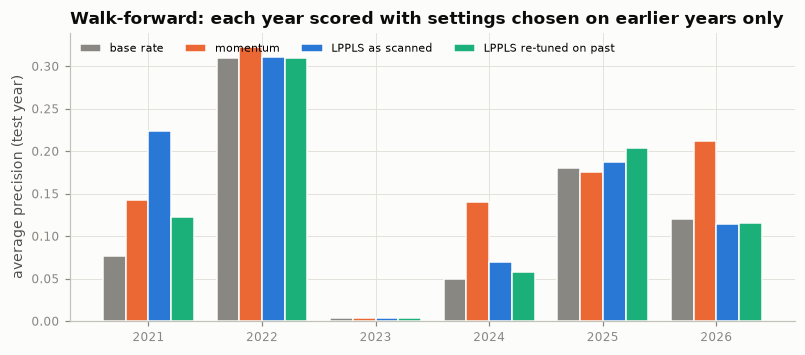

,test_year,n_train,n_test,base_rate_test,ap_stored_test,ap_momentum_test,ap_stored_train,ap_tuned_train,ap_tuned_test
0,2021,540,300,0.077,0.223,0.143,0.176,0.225,0.123
1,2022,840,300,0.310,0.311,0.323,0.109,0.134,0.310
2,2023,1140,300,0.003,0.003,0.004,0.183,0.193,0.003
3,2024,1440,300,0.050,0.070,0.140,0.156,0.163,0.058
4,2025,1740,300,0.180,0.187,0.176,0.130,0.140,0.203
5,2026,2040,192,0.120,0.115,0.212,0.139,0.149,0.115


In [9]:
if "walk_forward" in T and not T["walk_forward"].empty:
    display(figs["walk_forward.png"]); display(T["walk_forward"].round(3))
else:
    display(Markdown("_Walk-forward not in this report (run `make validate`)._"))

## 8 · False alarms on bubble-free prices

Each ticker's daily returns are reshuffled in blocks (stationary bootstrap, mean block of 20
days). This keeps volatility and short-term patterns but cannot produce a genuine bubble.
The detector is re-run on these simulated paths, with the same window grid for real and
simulated prices.

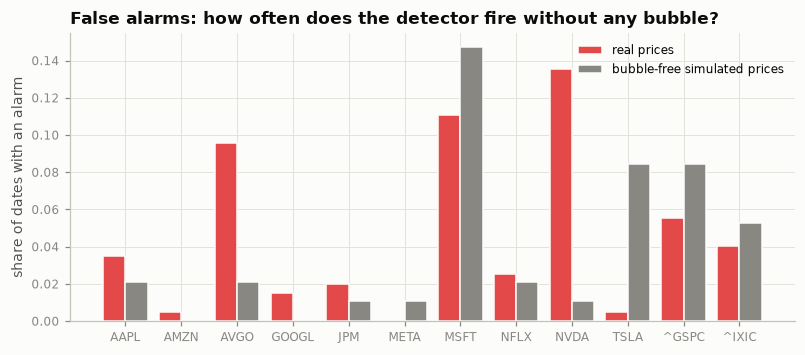

,alarm_rate_real,alarm_rate_null,mean_conf_real,mean_conf_null
ticker,,,,
AAPL,0.035,0.021,0.031,0.026
AMZN,0.005,0.000,0.016,0.010
AVGO,0.095,0.021,0.071,0.033
GOOGL,0.015,0.000,0.025,0.012
JPM,0.020,0.011,0.031,0.023
META,0.000,0.011,0.006,0.019
MSFT,0.111,0.147,0.085,0.094
NFLX,0.025,0.021,0.031,0.021
NVDA,0.136,0.011,0.083,0.020


In [10]:
if "null_model" in T and not T["null_model"].empty:
    display(figs["null_model.png"])
    display(T["null_model"].groupby("ticker")[["alarm_rate_real", "alarm_rate_null", "mean_conf_real", "mean_conf_null"]].mean().round(3))
else:
    display(Markdown("_Null model not in this report (run `make validate`)._"))

## 9 · Would it have helped an investor?

Equal-weight portfolio of all scanned tickers. **LPPLS de-risk** halves a ticker's exposure
from the day after an alarm until the next analysis date, with 10 bp costs per change.
**Momentum de-risk** does the same with the momentum score, at the *same* overall alarm rate.
The **placebo** uses the LPPLS alarms shifted randomly in time. The dotted line marks the
start of the validation period.

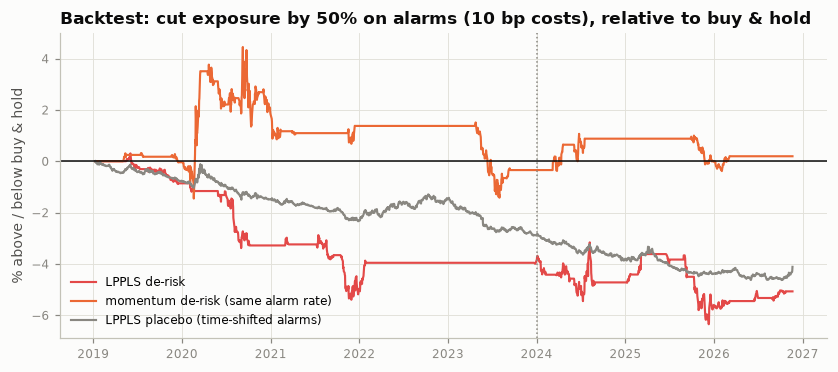

In [11]:
display(figs["backtest.png"])
bt = T["backtest"].set_index(["period", "strategy"])[["ann_return", "ann_vol", "sharpe", "max_drawdown", "avg_exposure"]]
bt.style.format({"ann_return": "{:.1%}", "ann_vol": "{:.1%}", "sharpe": "{:.2f}", "max_drawdown": "{:.1%}", "avg_exposure": "{:.1%}"}, na_rep="–")

## Reading the results

* **Skill and significance (sections 1, 3, 4).** Look at the *validation* column and the
  intervals. An AP a little above the base rate with an interval crossing 0, or a large placebo
  p-value, means no demonstrable predictive skill for this event definition.
* **Calibration (2).** Without a rising pattern, a confidence of 0.6 is not more alarming than 0.3.
* **Timing (6).** The episodes show what the score *does* capture: alarms cluster in strong
  rallies that continue for months before larger-than-usual falls. That is early and
  imprecise timing, not a crash forecast.
* **Walk-forward (7).** If re-tuned settings do not beat the scanned ones on the next year,
  tuning only fits the past.
* **Null model (8).** If bubble-free paths trigger alarms about as often as real prices, an
  alarm on its own is weak evidence of a bubble.
* **Backtest (9).** The practical bottom line. Compare with the momentum and placebo rows, not
  only with buy & hold.

Re-run with `make validate` after a new scan. Every report is also logged to MLflow
(experiment `lppl-validation`).